In [1]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Input: Study hours
X = np.array([
    [1], [2], [3], [4], [5],
    [6], [7], [8], [9], [10]
])

# Output: 0 = Fail, 1 = Pass
y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create model
model = LogisticRegression()

# Train model
model.fit(X_train, y_train)

# Predict classes
y_pred = model.predict(X_test)

# Predict probabilities
y_prob = model.predict_proba(X_test)

print("Predicted classes:", y_pred)
print("Predicted probabilities:\n", y_prob)
print("Accuracy:", accuracy_score(y_test, y_pred))

# Predict for a student who studies 7 hours
new_student = np.array([[7]])

print("Predicted class:", model.predict(new_student)[0])
print("Probability of passing:", model.predict_proba(new_student)[0][1])

Predicted classes: [0 1]
Predicted probabilities:
 [[0.80609138 0.19390862]
 [0.00607677 0.99392323]]
Accuracy: 1.0
Predicted class: 1
Probability of passing: 0.8624972772126834


In [2]:
import numpy as np

class LogisticRegression:
    def __init__(self, learning_rate=0.01, epochs=10000):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0

        for _ in range(self.epochs):
            # Forward propagation
            z = np.dot(X, self.weights) + self.bias
            y_pred = self.sigmoid(z)

            # Calculate gradients
            dw = np.dot(X.T, (y_pred - y)) / n_samples
            db = np.mean(y_pred - y)

            # Update weights and bias
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.sigmoid(z)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return (probabilities >= 0.5).astype(int)


# Dataset
X = np.array([
    [1], [2], [3], [4], [5],
    [6], [7], [8], [9], [10]
], dtype=float)

y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

# Train model
model = LogisticRegression(learning_rate=0.01, epochs=10000)
model.fit(X, y)

# Predictions
print("Weights:", model.weights)
print("Bias:", model.bias)
print("Predicted classes:", model.predict(X))
print("Probabilities:", model.predict_proba(X))

# Predict a new sample
new_data = np.array([[7.0]])

print("New prediction:", model.predict(new_data))
print("Probability:", model.predict_proba(new_data))

Weights: [1.07953121]
Bias: -5.661862466869316
Predicted classes: [0 0 0 0 0 1 1 1 1 1]
Probabilities: [0.0101274  0.02923267 0.08141545 0.20689608 0.43432996 0.69324302
 0.86930822 0.95140352 0.98294179 0.99413838]
New prediction: [1]
Probability: [0.86930822]


Weights: [1.07953121]
Bias: -5.661862466869316
Predictions: [0 0 0 0 0 1 1 1 1 1]
Probabilities: [0.0101274  0.02923267 0.08141545 0.20689608 0.43432996 0.69324302
 0.86930822 0.95140352 0.98294179 0.99413838]


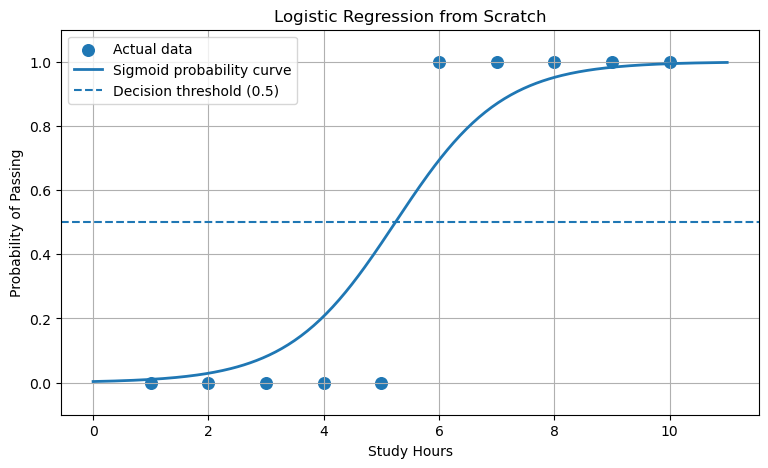

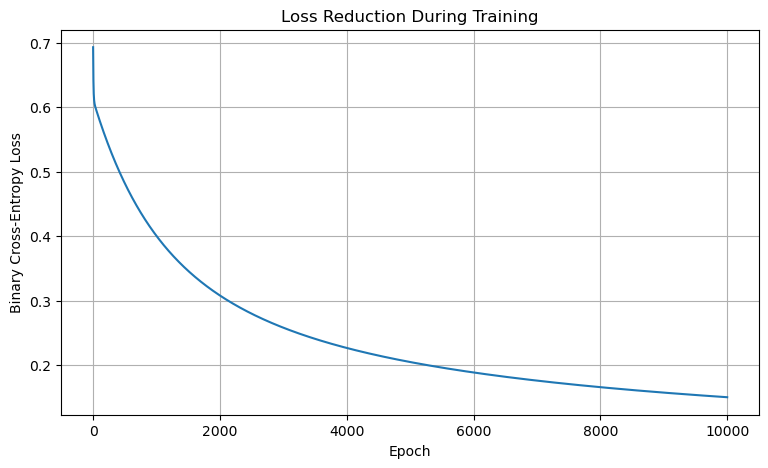

In [3]:
import numpy as np
import matplotlib.pyplot as plt


class LogisticRegression:
    def __init__(self, learning_rate=0.01, epochs=10000):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.losses = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0
        self.losses = []

        for _ in range(self.epochs):

            # Forward propagation
            z = np.dot(X, self.weights) + self.bias
            y_pred = self.sigmoid(z)

            # Binary cross-entropy loss
            eps = 1e-15
            p = np.clip(y_pred, eps, 1 - eps)

            loss = -np.mean(
                y * np.log(p) + (1 - y) * np.log(1 - p)
            )
            self.losses.append(loss)

            # Calculate gradients
            dw = np.dot(X.T, (y_pred - y)) / n_samples
            db = np.mean(y_pred - y)

            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.sigmoid(z)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return (probabilities >= 0.5).astype(int)


# Dataset
X = np.array([
    [1], [2], [3], [4], [5],
    [6], [7], [8], [9], [10]
], dtype=float)

# 0 = Fail, 1 = Pass
y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

# Train model
model = LogisticRegression(learning_rate=0.01, epochs=10000)
model.fit(X, y)

# Predictions
print("Weights:", model.weights)
print("Bias:", model.bias)
print("Predictions:", model.predict(X))
print("Probabilities:", model.predict_proba(X))

# Create smooth X values for the sigmoid curve
X_curve = np.linspace(0, 11, 300).reshape(-1, 1)
probabilities = model.predict_proba(X_curve)

# --------------------------------
# GRAPH 1: Logistic Regression
# --------------------------------
plt.figure(figsize=(9, 5))

plt.scatter(
    X.flatten(), y,
    label="Actual data",
    s=70
)

plt.plot(
    X_curve.flatten(), probabilities,
    label="Sigmoid probability curve",
    linewidth=2
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="Decision threshold (0.5)"
)

plt.xlabel("Study Hours")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression from Scratch")
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(True)
plt.show()


# --------------------------------
# GRAPH 2: Gradient Descent Loss
# --------------------------------
plt.figure(figsize=(9, 5))

plt.plot(model.losses)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Loss Reduction During Training")
plt.grid(True)
plt.show()

In [4]:
import numpy as np
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Dataset
X = np.array([[1], [2], [3], [4], [5]], dtype=float)
y = np.array([2, 4, 6, 8, 10], dtype=float)

# Create model
model = make_pipeline(
    StandardScaler(),
    SGDRegressor(
        loss="squared_error",
        learning_rate="constant",
        eta0=0.01,
        max_iter=5000,
        tol=1e-6,
        random_state=42
    )
)

# Train model
model.fit(X, y)

# Predictions
y_pred = model.predict(X)

print("Predictions:", y_pred)
print("MSE:", mean_squared_error(y, y_pred))
print("R2 Score:", r2_score(y, y_pred))

# Predict for a new value
print("Prediction for 6:", model.predict([[6]])[0])

Predictions: [1.99942835 3.99826069 5.99709303 7.99592536 9.9947577 ]
MSE: 1.1177367049212486e-05
R2 Score: 0.9999986028291189
Prediction for 6: 11.993590038833776
